# Import modules

In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime, timezone
sys.path.insert(0, str(Path.cwd().parent))  # src/ when the notebook is in src/model/

from core.io import create_supabase_client
from core.config import POLLUTANT_COLUMNS
from model.train import USEFUL_FEATURES
from model.io import load_gold

client = create_supabase_client()
df = load_gold(client)
df = df[USEFUL_FEATURES]

2026-11-09 12:24:18,182 | INFO | core.io | Read 146190 rows from air_pollution_gold
2026-11-09 12:24:18,184 | INFO | model.load | 146190 rows fetched from gold table


# Basic info of the gold records

In [2]:
print(f"Features: {df.columns.to_list()}")
display(df.head())

Features: ['city', 'latitude', 'longitude', 'timestamp', 'aqi', 'co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10', 'nh3', 'time_of_day', 'day_of_week', 'year']


,city,latitude,longitude,timestamp,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3,time_of_day,day_of_week,year
0,Fremont,37.5485,-121.9886,2026-10-21T02:19:03+00:00,2,145.19,0.00,1.65,81.80,1.00,2.38,5.45,0.01,Evening,Tuesday,2026
1,Fremont,37.5485,-121.9886,2026-10-22T19:26:10+00:00,2,139.79,0.12,1.27,75.63,0.55,2.71,3.25,0.00,Afternoon,Thursday,2026
2,Fremont,37.5485,-121.9886,2026-10-22T19:44:14+00:00,2,141.28,0.12,1.14,78.04,0.59,3.17,3.85,0.00,Afternoon,Thursday,2026
3,San Francisco,37.7749,-122.4194,2026-10-21T02:19:04+00:00,2,139.61,0.00,1.07,79.02,0.77,1.55,3.58,0.00,Evening,Tuesday,2026
4,San Francisco,37.7749,-122.4194,2026-10-22T19:17:46+00:00,2,149.65,0.13,1.08,81.99,0.44,4.96,5.98,0.00,Afternoon,Thursday,2026


In [3]:
display(df["time_of_day"].value_counts())

time_of_day
Night        48734
Morning      42637
Afternoon    30459
Evening      24360
Name: count, dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 146190 entries, 0 to 146189
Data columns (total 16 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   city         146190 non-null  str    
 1   latitude     146190 non-null  float64
 2   longitude    146190 non-null  float64
 3   timestamp    146190 non-null  str    
 4   aqi          146190 non-null  int64  
 5   co           146190 non-null  float64
 6   no           146190 non-null  float64
 7   no2          146190 non-null  float64
 8   o3           146190 non-null  float64
 9   so2          146190 non-null  float64
 10  pm2_5        146190 non-null  float64
 11  pm10         146190 non-null  float64
 12  nh3          146190 non-null  float64
 13  time_of_day  146190 non-null  str    
 14  day_of_week  146190 non-null  str    
 15  year         146190 non-null  int64  
dtypes: float64(10), int64(2), str(4)
memory usage: 24.4 MB


# Basic encoding

In [5]:
TIME_OF_DAY = {
    k: v for v, k in enumerate(["Morning", "Afternoon", "Evening", "Night"])
}
DAY_OF_WEEK = {
    k: v for v, k in enumerate(["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"])
}

def basic_encoding(row: pd.Series) -> pd.Series:
    row["time_of_day"] = TIME_OF_DAY.get(row["time_of_day"])
    row["day_of_week"] = DAY_OF_WEEK.get(row["day_of_week"])
    return row

In [6]:
df = df.apply(basic_encoding, axis=1)
df.head()

,city,latitude,longitude,timestamp,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3,time_of_day,day_of_week,year
0,Fremont,37.5485,-121.9886,2026-10-21T02:19:03+00:00,2,145.19,0.00,1.65,81.80,1.00,2.38,5.45,0.01,2,2,2026
1,Fremont,37.5485,-121.9886,2026-10-22T19:26:10+00:00,2,139.79,0.12,1.27,75.63,0.55,2.71,3.25,0.00,1,4,2026
2,Fremont,37.5485,-121.9886,2026-10-22T19:44:14+00:00,2,141.28,0.12,1.14,78.04,0.59,3.17,3.85,0.00,1,4,2026
3,San Francisco,37.7749,-122.4194,2026-10-21T02:19:04+00:00,2,139.61,0.00,1.07,79.02,0.77,1.55,3.58,0.00,2,2,2026
4,San Francisco,37.7749,-122.4194,2026-10-22T19:17:46+00:00,2,149.65,0.13,1.08,81.99,0.44,4.96,5.98,0.00,1,4,2026


# Curated info

In [7]:
cities = df["city"].unique()
for city in cities:
    print(f"Data description of air pollutants in {city}")
    display(df.loc[df["city"] == city, ["aqi"] + POLLUTANT_COLUMNS].describe().round(2))

Data description of air pollutants in Fremont


,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00
mean,2.12,247.96,3.59,14.47,67.47,1.95,10.04,16.73,0.93
std,0.73,196.50,10.69,93.67,34.50,2.03,15.06,66.52,1.85
min,1.00,71.85,0.00,-9999.00,0.00,0.09,0.00,-9999.00,0.00
25%,2.00,114.01,0.00,0.90,50.81,0.82,3.02,7.45,0.00
50%,2.00,176.35,0.06,3.47,72.96,1.19,4.75,12.65,0.12
75%,2.00,300.41,0.89,19.55,88.55,2.32,9.86,20.02,0.97
max,5.00,1789.09,109.97,180.96,371.93,27.89,197.65,227.24,20.52


Data description of air pollutants in San Francisco


,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00,24363.00
mean,2.06,231.32,3.35,10.57,70.52,2.04,7.98,14.52,0.56
std,0.63,198.69,12.73,93.03,27.85,2.68,12.47,65.95,1.30
min,1.00,70.78,0.00,-9999.00,0.00,0.08,0.00,-9999.00,0.00
25%,2.00,110.36,0.00,0.66,59.37,0.74,2.63,6.13,0.00
50%,2.00,153.57,0.03,1.86,75.82,1.08,4.15,11.39,0.00
75%,2.00,263.69,0.33,10.02,88.84,2.18,7.27,17.78,0.49
max,5.00,1976.01,178.81,159.03,331.88,28.37,152.72,173.49,15.71


Data description of air pollutants in Austin


,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00
mean,1.66,190.86,0.31,3.89,62.70,1.00,4.95,7.53,1.04
std,0.66,84.45,1.17,90.87,26.80,0.70,3.75,64.46,1.00
min,1.00,69.37,0.00,-9999.00,0.00,0.09,0.00,-9999.00,0.00
25%,1.00,117.90,0.00,1.56,42.03,0.55,2.28,3.80,0.37
50%,2.00,168.70,0.02,2.68,60.80,0.78,3.91,6.57,0.75
75%,2.00,250.34,0.20,5.44,81.54,1.22,6.49,10.26,1.35
max,4.00,841.14,27.49,70.60,163.08,6.26,47.96,162.55,13.30


... (2 outputs left out)

Data description of air pollutants in Atlanta


,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,24336.0,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00,24336.00
mean,1.7,216.43,1.21,7.89,58.21,1.62,6.32,7.99,1.17
std,0.7,120.07,5.39,91.61,32.52,1.82,5.54,64.54,1.07
min,1.0,81.14,0.00,-9999.00,0.00,0.08,0.00,-9999.00,0.00
25%,1.0,129.40,0.00,2.27,33.87,0.41,2.92,3.97,0.47
50%,2.0,174.26,0.06,4.06,57.82,1.10,4.88,6.74,0.84
75%,2.0,273.70,0.37,9.42,79.39,2.06,7.96,10.54,1.52
max,5.0,1255.04,119.81,149.43,429.15,23.84,86.67,99.36,14.31


Data description of air pollutants in Denver


,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,24408.00,24408.00,24408.00,24408.00,24408.00,24408.00,24408.00,24408.00,24408.00
mean,1.93,241.13,5.01,15.30,61.46,1.61,7.10,8.74,2.04
std,0.77,237.80,14.72,94.28,32.69,2.51,12.44,65.62,2.33
min,1.00,56.76,0.00,-9999.00,0.00,0.00,0.00,-9999.00,0.00
25%,1.00,93.05,0.00,1.11,39.93,0.11,1.29,1.78,0.51
50%,2.00,122.54,0.04,3.06,63.27,0.36,2.70,4.10,1.12
75%,2.00,293.73,0.73,20.91,84.43,2.26,7.08,9.97,2.72
max,5.00,1895.90,146.63,202.89,223.16,27.42,163.36,176.95,18.24


# Feature Engineering

## Time related features

In [8]:
def get_time_info(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "timestamp" not in df:
        print("Already processed.")
        return df
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["hour"] = df["timestamp"].dt.hour
    df["day"] = df["timestamp"].dt.day
    df["month"] = df["timestamp"].dt.month
    return df# .drop("timestamp", axis=1)

df = get_time_info(df)
df.head()

,city,latitude,longitude,timestamp,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3,time_of_day,day_of_week,year,hour,day,month
0,Fremont,37.5485,-121.9886,2026-10-21 02:19:03+00:00,2,145.19,0.00,1.65,81.80,1.00,2.38,5.45,0.01,2,2,2026,2,21,10
1,Fremont,37.5485,-121.9886,2026-10-22 19:26:10+00:00,2,139.79,0.12,1.27,75.63,0.55,2.71,3.25,0.00,1,4,2026,19,22,10
2,Fremont,37.5485,-121.9886,2026-10-22 19:44:14+00:00,2,141.28,0.12,1.14,78.04,0.59,3.17,3.85,0.00,1,4,2026,19,22,10
3,San Francisco,37.7749,-122.4194,2026-10-21 02:19:04+00:00,2,139.61,0.00,1.07,79.02,0.77,1.55,3.58,0.00,2,2,2026,2,21,10
4,San Francisco,37.7749,-122.4194,2026-10-22 19:17:46+00:00,2,149.65,0.13,1.08,81.99,0.44,4.96,5.98,0.00,1,4,2026,19,22,10


In [9]:
def add_periodicity(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["time_of_day_sin"] = np.sin(df["time_of_day"] * np.pi/ 2)
    df["time_of_day_cos"] = np.cos(df["time_of_day"] * np.pi/ 2)
    df["day_of_week_sin"] = np.sin(2 * df["day_of_week"] * np.pi/ 7)
    df["day_of_week_cos"] = np.cos(2 * df["day_of_week"] * np.pi/ 7)
    df["hour_sin"] = np.sin(df["hour"] * np.pi/ 12)
    df["hour_cos"] = np.cos(df["hour"] * np.pi/ 12)
    df["day_sin"] = np.sin(df["day"] * np.pi/ 15)
    df["day_cos"] = np.cos(df["day"] * np.pi/ 15)
    df["month_sin"] = np.sin(df["month"] * np.pi/ 6)
    df["month_cos"] = np.cos(df["month"] * np.pi/ 6)
    return df

df = add_periodicity(df)
df.head()

,city,latitude,longitude,timestamp,aqi,co,no,no2,o3,so2,...,time_of_day_sin,time_of_day_cos,day_of_week_sin,day_of_week_cos,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos
0,Fremont,37.5485,-121.9886,2026-10-21 02:19:03+00:00,2,145.19,0.00,1.65,81.80,1.00,...,1.224647e-16,-1.000000e+00,0.974928,-0.222521,0.500000,0.866025,-0.951057,-0.309017,-0.866025,0.5
1,Fremont,37.5485,-121.9886,2026-10-22 19:26:10+00:00,2,139.79,0.12,1.27,75.63,0.55,...,1.000000e+00,6.123234e-17,-0.433884,-0.900969,-0.965926,0.258819,-0.994522,-0.104528,-0.866025,0.5
2,Fremont,37.5485,-121.9886,2026-10-22 19:44:14+00:00,2,141.28,0.12,1.14,78.04,0.59,...,1.000000e+00,6.123234e-17,-0.433884,-0.900969,-0.965926,0.258819,-0.994522,-0.104528,-0.866025,0.5
3,San Francisco,37.7749,-122.4194,2026-10-21 02:19:04+00:00,2,139.61,0.00,1.07,79.02,0.77,...,1.224647e-16,-1.000000e+00,0.974928,-0.222521,0.500000,0.866025,-0.951057,-0.309017,-0.866025,0.5
4,San Francisco,37.7749,-122.4194,2026-10-22 19:17:46+00:00,2,149.65,0.13,1.08,81.99,0.44,...,1.000000e+00,6.123234e-17,-0.433884,-0.900969,-0.965926,0.258819,-0.994522,-0.104528,-0.866025,0.5


## Lagged info

In [10]:
lags = [1, 3, 8, 24]
def add_lagged_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values(["city", "timestamp"]).reset_index(drop=True)

    df = (
        df.set_index("timestamp")
        .groupby("city")
        .resample("1h") # Fill in missing hours
        .asfreq() # By NaN
        .reset_index()
    )

    g = df.groupby("city")

    # Lagged values of every pollutant
    for col in POLLUTANT_COLUMNS:
        for lag in lags:
            df[f"{col}_lag{lag}"] = g[col].shift(lag)

    # Rolling mean and min/max
    for col in POLLUTANT_COLUMNS:
        df[f"{col}_mean24"] = g[col].transform(lambda s: s.shift(1).rolling(24).mean())
        df[f"{col}_max24"] = g[col].transform(lambda s: s.shift(1).rolling(24).max())
        df[f"{col}_min24"] = g[col].transform(lambda s: s.shift(1).rolling(24).min())

    # Create target values: 24 hours into the future
    for col in POLLUTANT_COLUMNS:
        df[f"{col}_target"] = g[col].shift(-24)

    return df.dropna()

add_lagged_data(df).head()

,city,timestamp,latitude,longitude,aqi,co,no,no2,o3,so2,...,nh3_max24,nh3_min24,co_target,no_target,no2_target,o3_target,so2_target,pm2_5_target,pm10_target,nh3_target
24,Atlanta,2024-01-02 08:00:00+00:00,33.749,-84.388,1.0,297.07,0.01,9.94,40.77,2.95,...,1.35,0.74,460.62,3.91,33.24,1.34,1.33,12.96,17.87,1.36
25,Atlanta,2024-01-02 09:00:00+00:00,33.749,-84.388,1.0,303.75,0.02,10.97,37.55,2.89,...,1.36,0.74,440.60,3.49,30.16,1.61,1.49,12.72,17.57,1.60
26,Atlanta,2024-01-02 10:00:00+00:00,33.749,-84.388,1.0,310.42,0.03,12.34,33.62,2.74,...,1.55,0.74,427.25,3.32,28.10,1.94,1.62,12.82,17.55,1.74
27,Atlanta,2024-01-02 11:00:00+00:00,33.749,-84.388,1.0,323.77,0.08,15.08,28.61,2.62,...,1.77,0.74,420.57,3.52,26.73,2.37,1.71,13.13,17.69,1.96
28,Atlanta,2024-01-02 12:00:00+00:00,33.749,-84.388,1.0,367.16,0.57,23.65,18.06,2.68,...,2.03,0.75,467.30,8.61,29.47,1.07,1.85,15.87,21.12,2.91


In [11]:
df[POLLUTANT_COLUMNS].mean()

co       267.355682
no         5.999255
no2       15.286093
o3        65.246061
so2        2.578299
pm2_5     10.854746
pm10      15.992076
nh3        1.308234
dtype: float64

## Graphs of pollutants

In [22]:
def city_pollutants_lineplot(df: pd.DataFrame, city: str, time_frame: tuple | None=None):
    fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
    axes = axes.flatten()

    if not time_frame:
        df_plot = df.loc[df["city"] == city, ["timestamp"] + POLLUTANT_COLUMNS]
    else:
        df_plot = df.loc[(df["city"] == city) & (df["timestamp"] >= time_frame[0]) & (df["timestamp"] <= time_frame[1]), ["timestamp"] + POLLUTANT_COLUMNS]
    df_plot["timestamp"] = pd.to_datetime(df_plot["timestamp"])
    df_plot = df_plot.sort_values("timestamp")

    for ax, pollutant in zip(axes, POLLUTANT_COLUMNS):
        sns.lineplot(data=df_plot, x="timestamp", y=pollutant, ax=ax, errorbar=None)
        ax.set_title(f"Lineplot of {pollutant} against time")

    # Hide any unused axes if there are fewer than 8 pollutants
    for ax in axes[len(POLLUTANT_COLUMNS):]:
        ax.set_visible(False)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

def city_pollutants_boxplot(df: pd.DataFrame, city: str, time_frame: tuple | None=None):
    if time_frame:
        df_plot = df.loc[(df["city"] == city) & (df["timestamp"] >= time_frame[0]) & (df["timestamp"] <= time_frame[1]), POLLUTANT_COLUMNS]
    else:
        df_plot = df.loc[df["city"] == city, POLLUTANT_COLUMNS]
    sns.boxplot(data=df_plot)

    plt.tight_layout()
    plt.show()

Pollutant plot of Fremont


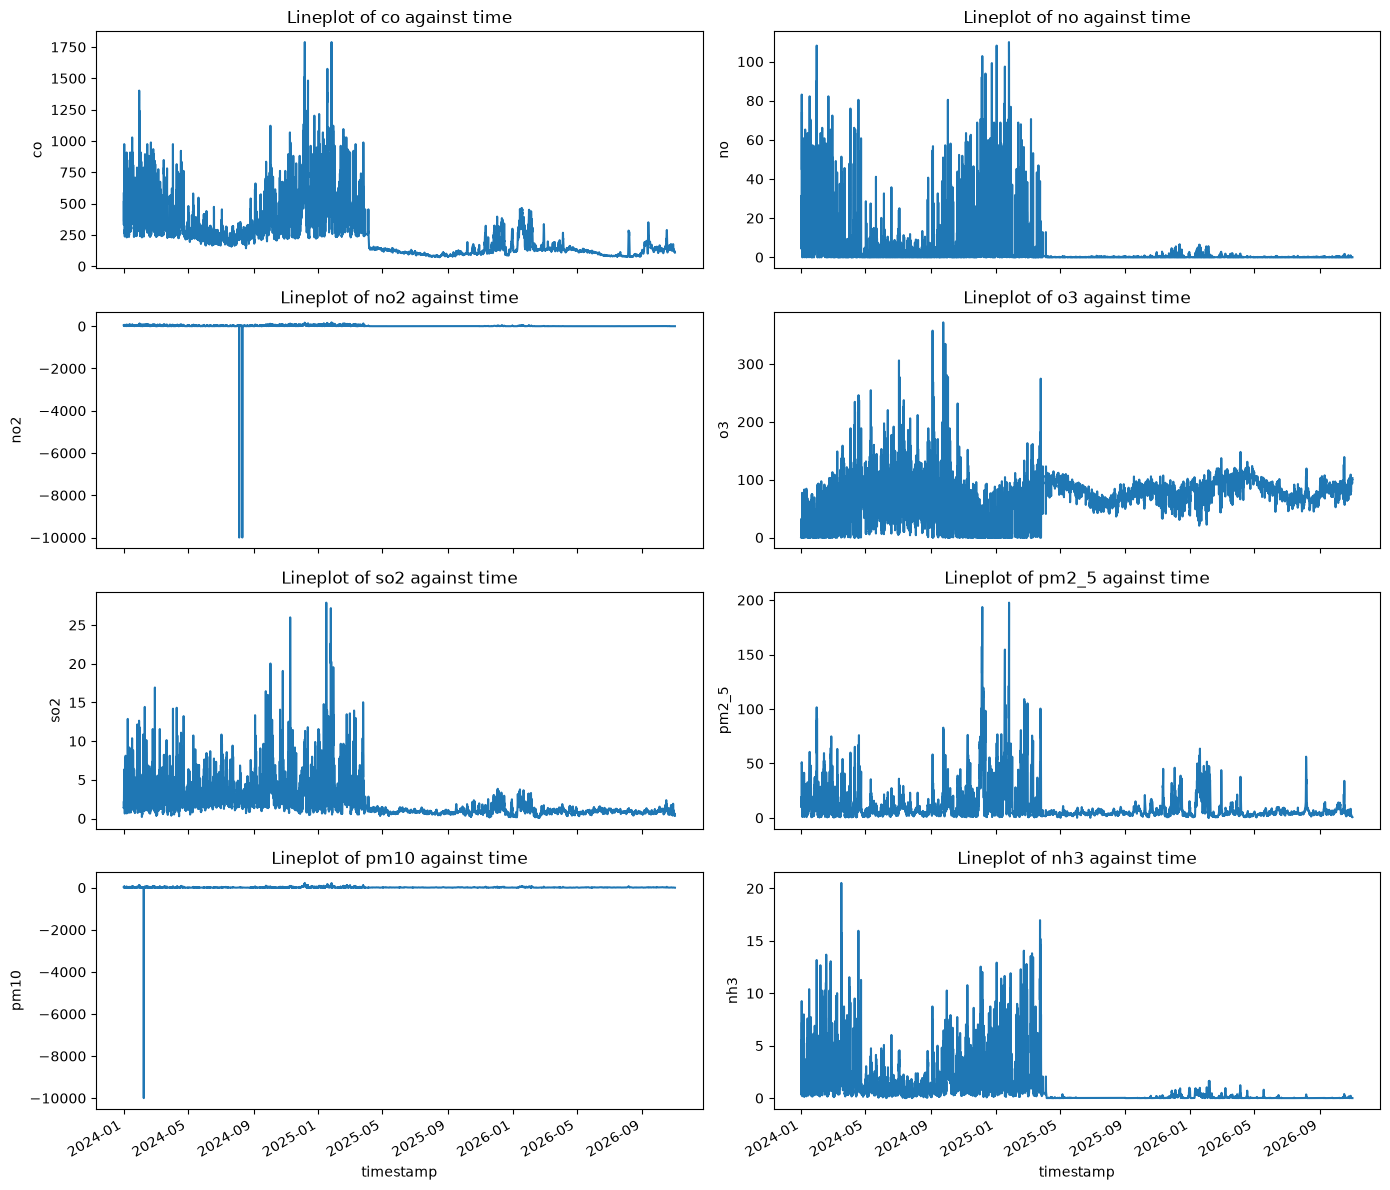

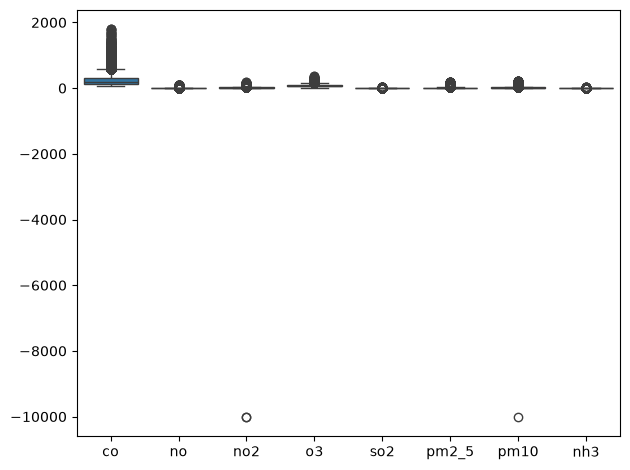

Pollutant plot of San Francisco


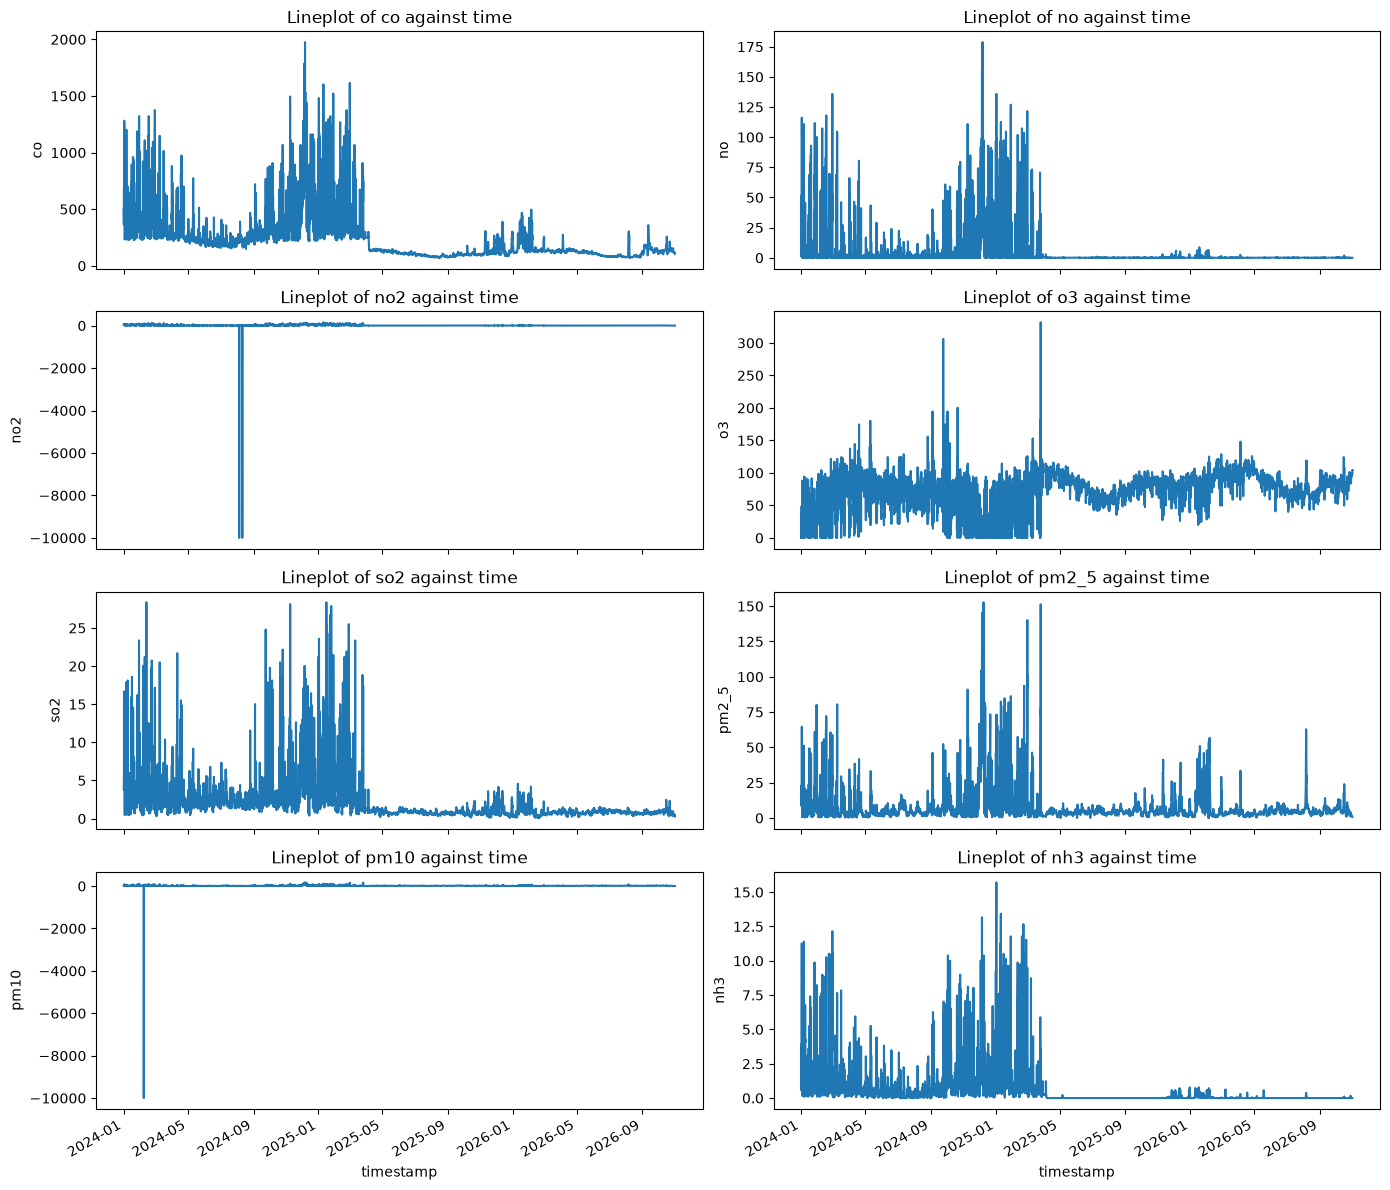

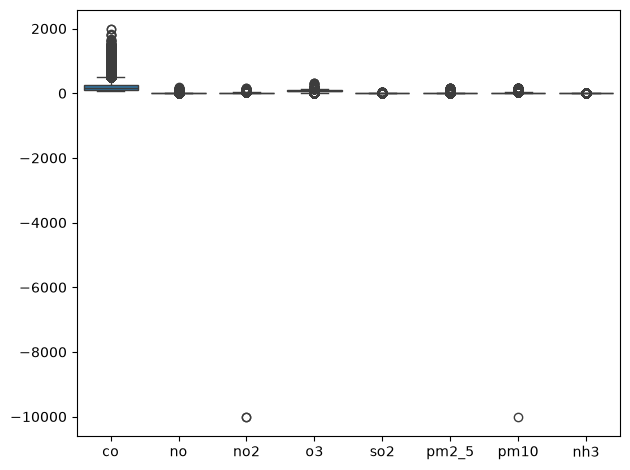

Pollutant plot of Austin


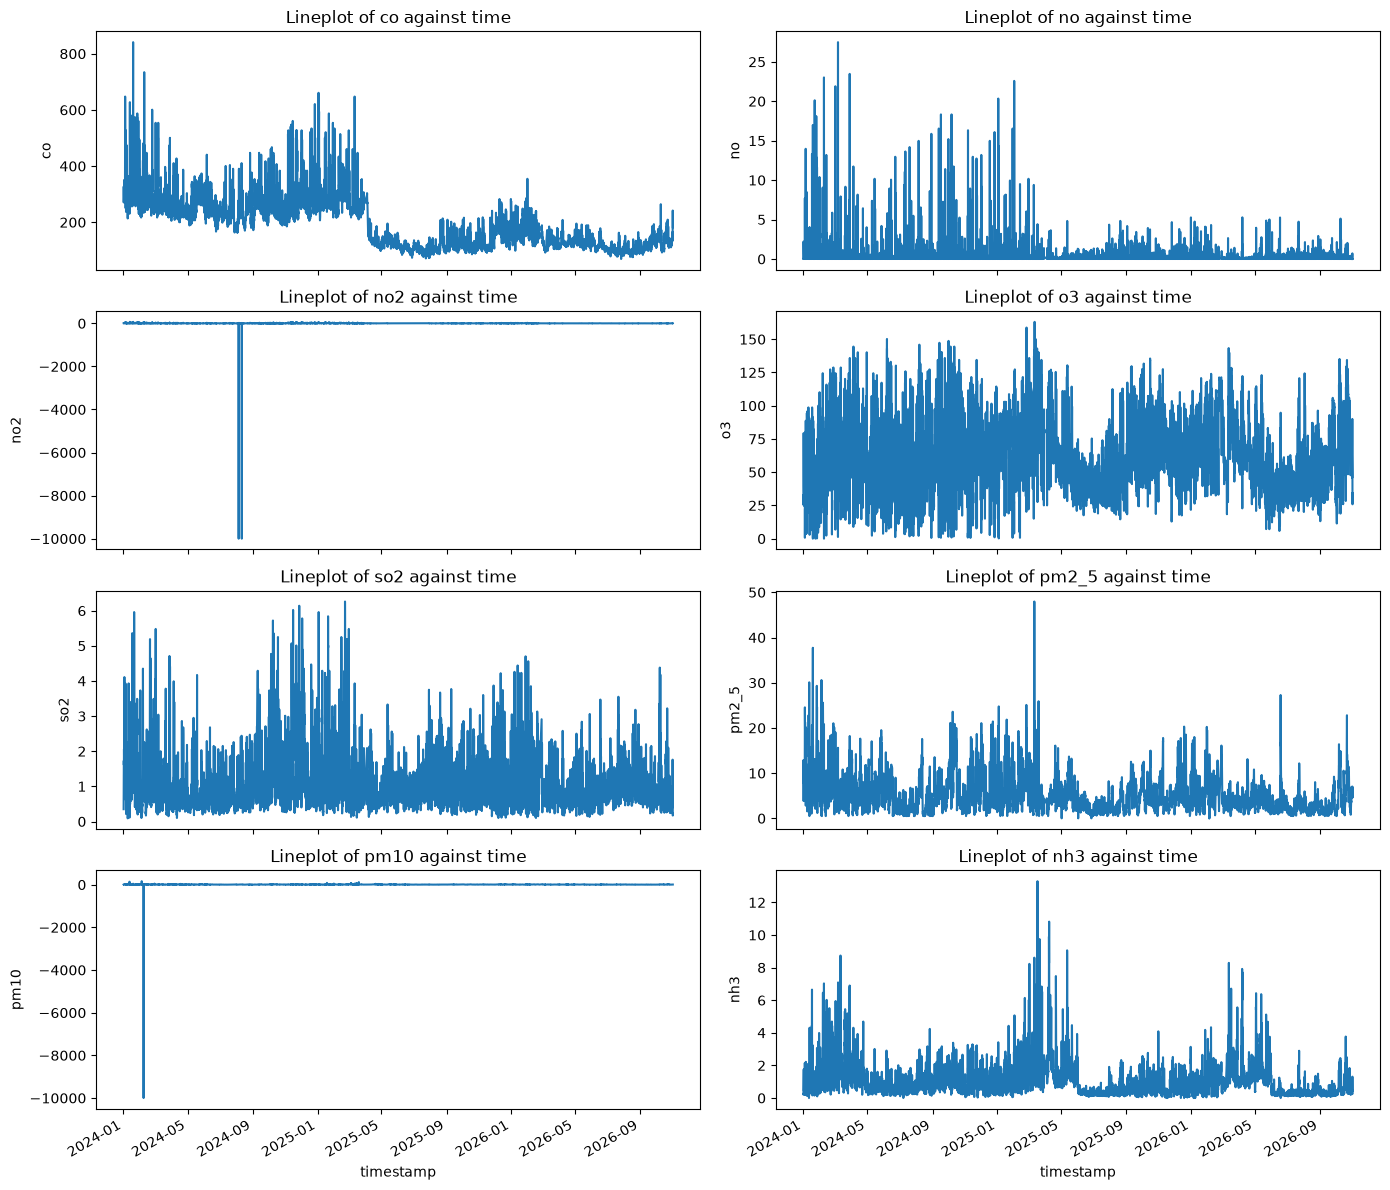

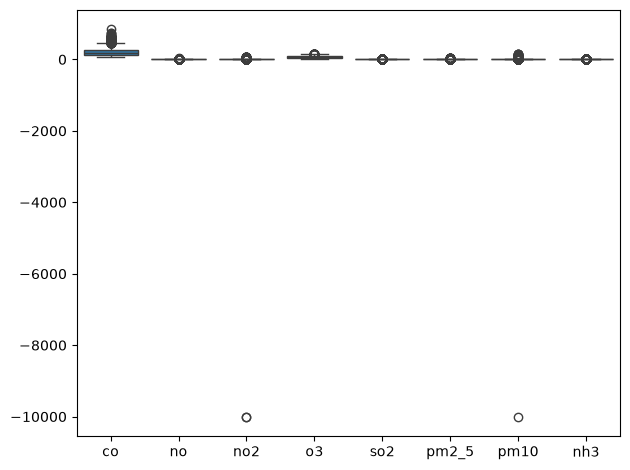

Pollutant plot of Los Angeles


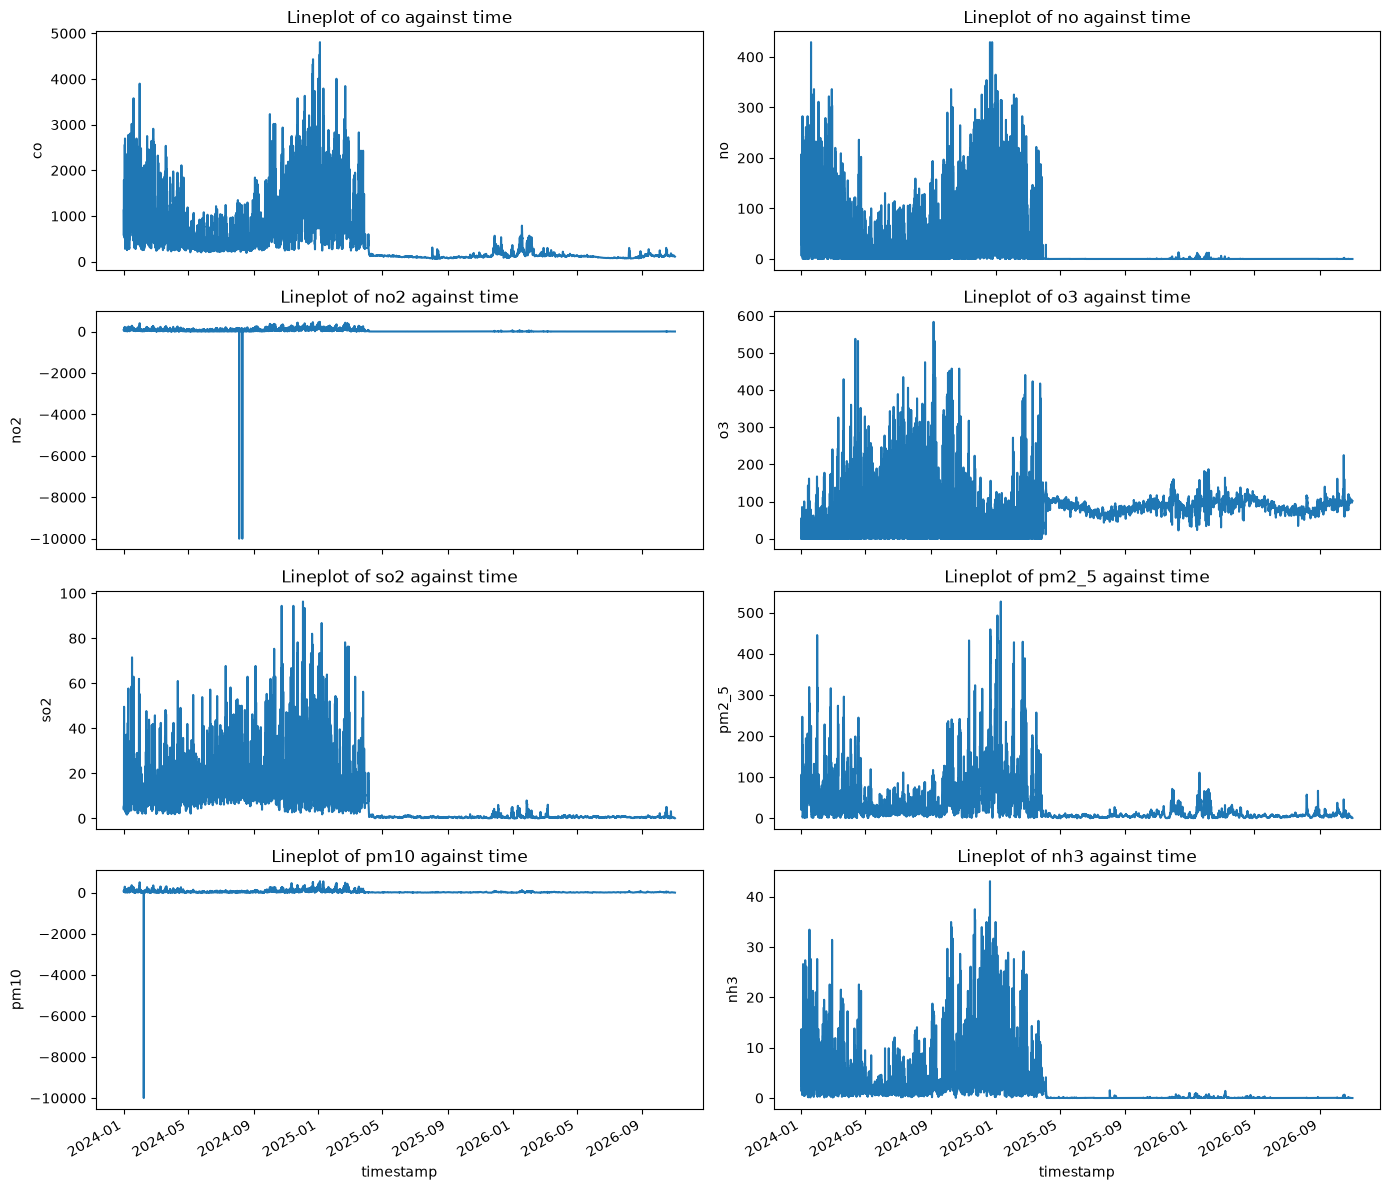

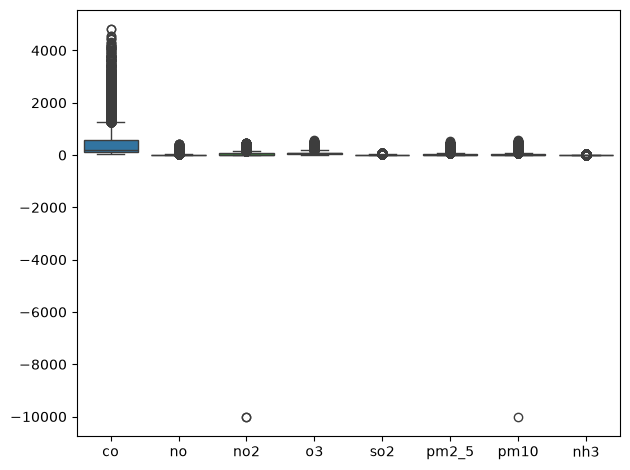

Pollutant plot of Atlanta


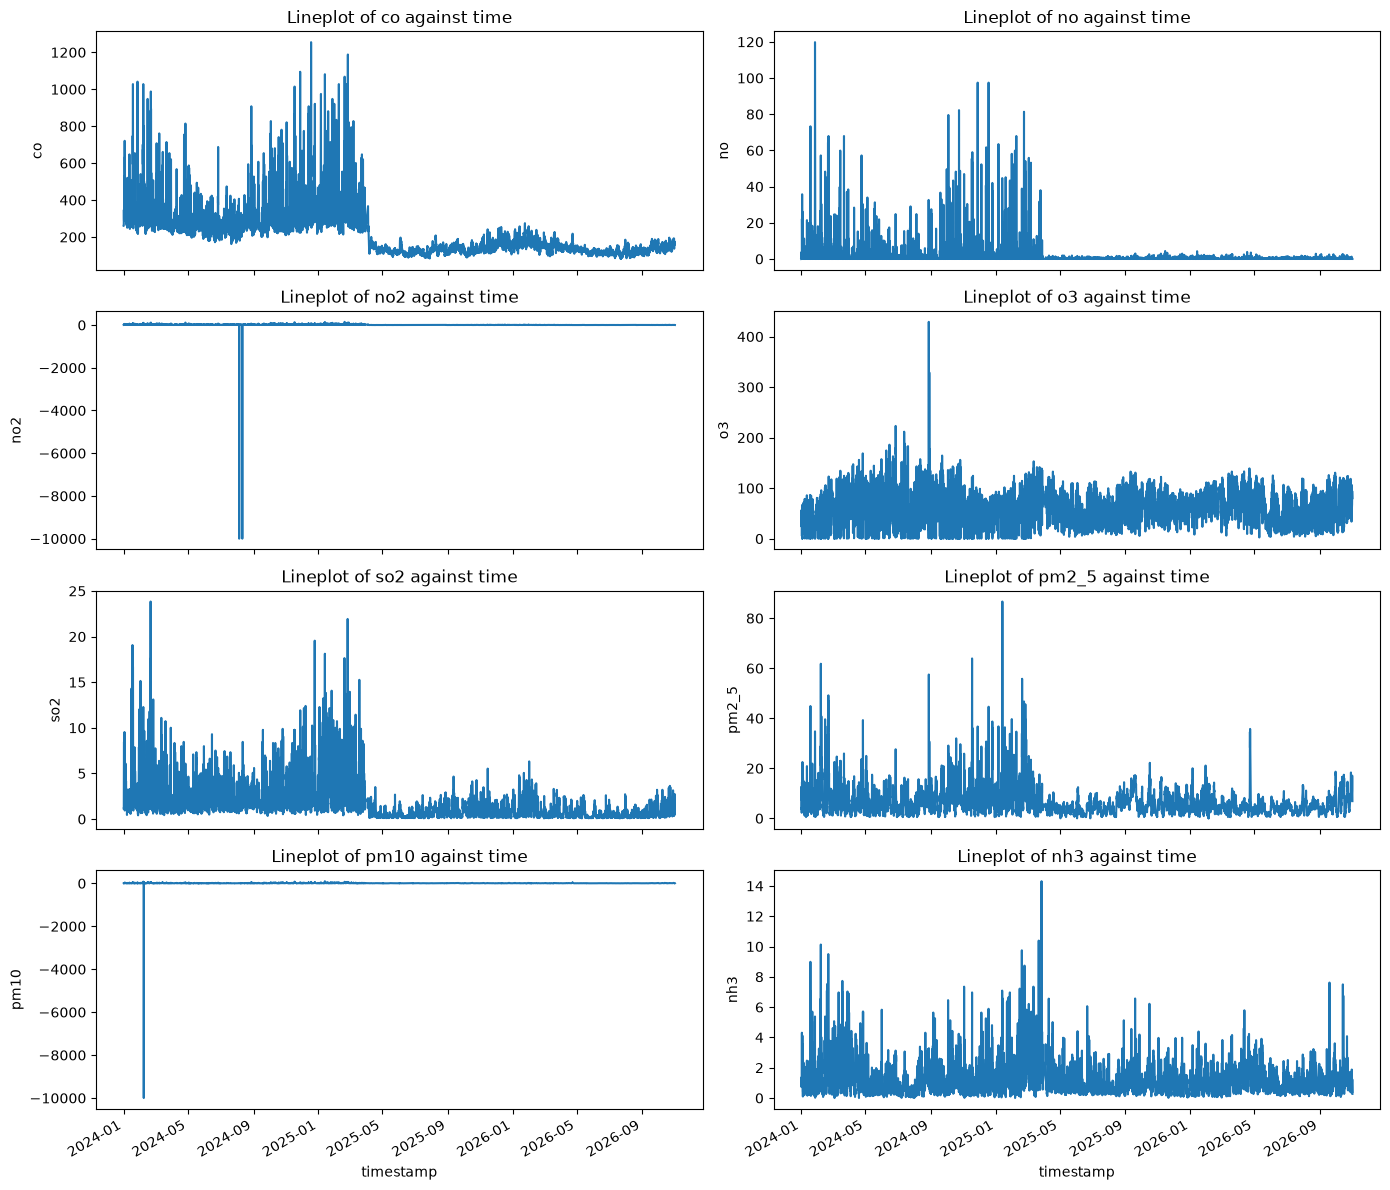

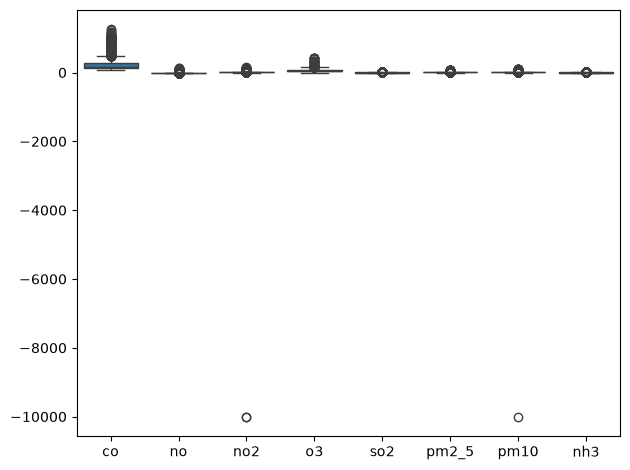

Pollutant plot of Denver


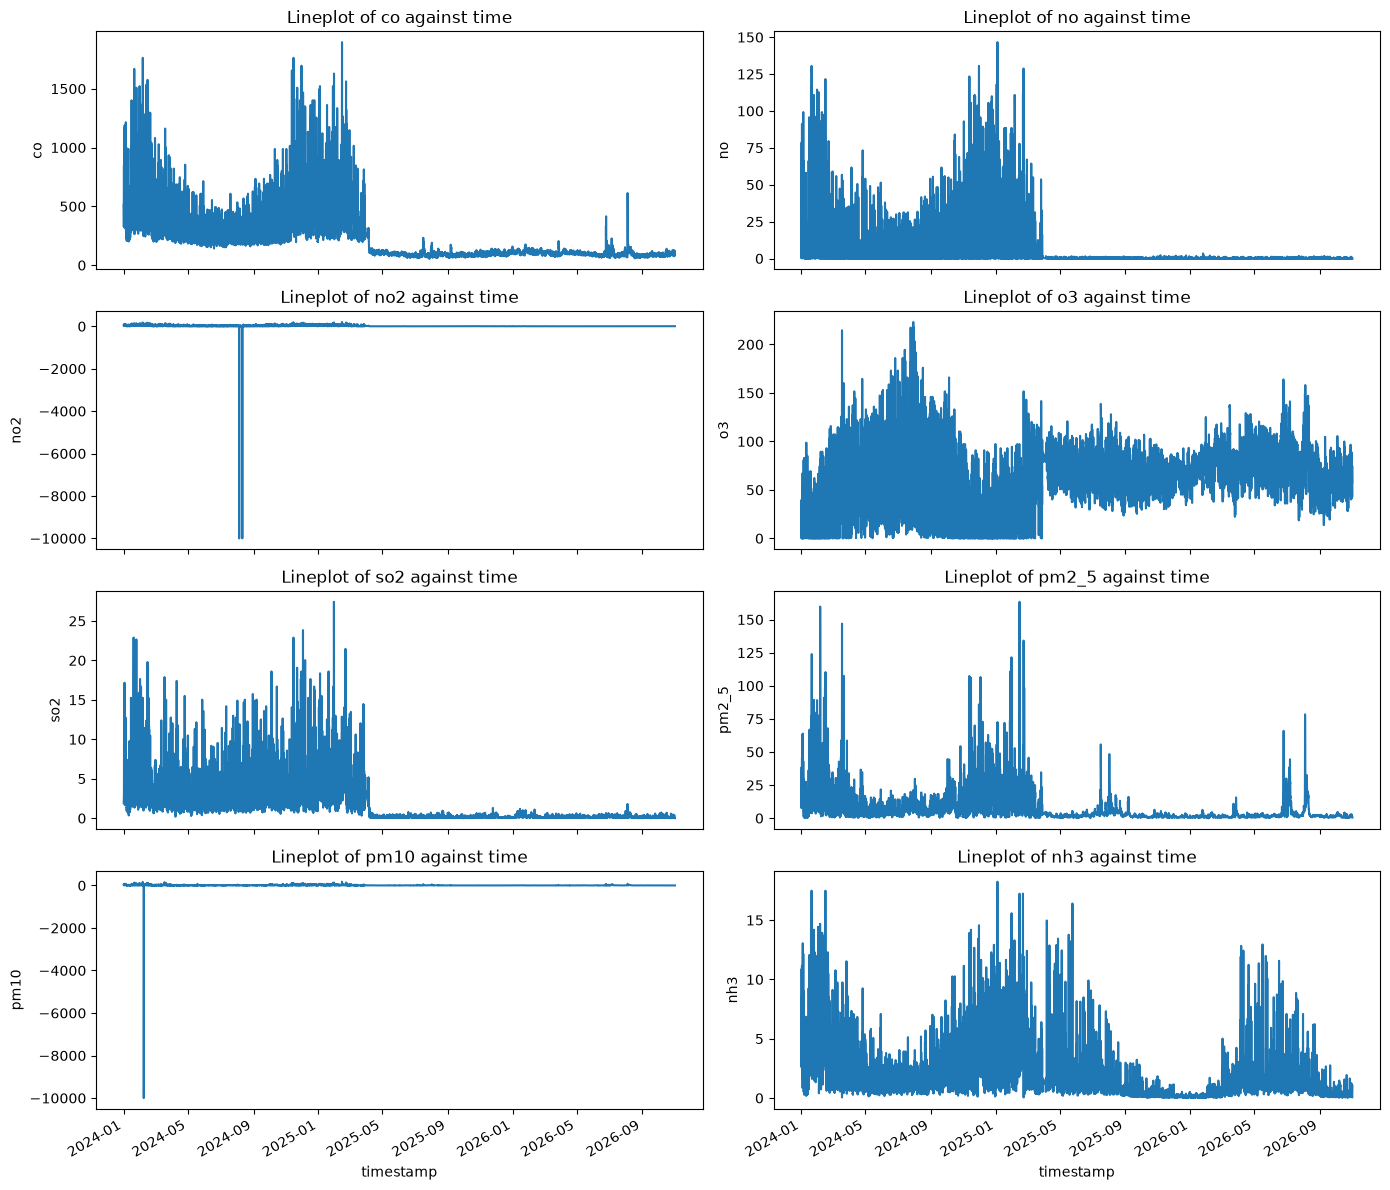

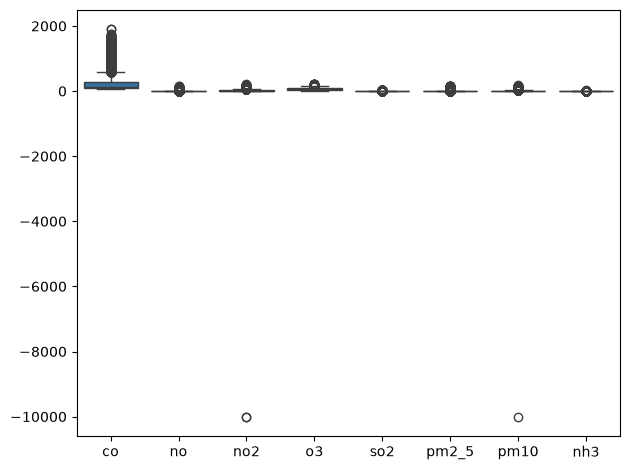

In [23]:
for city in df["city"].unique():
    print(f"Pollutant plot of {city}")
    city_pollutants_lineplot(df, city)
    city_pollutants_boxplot(df, city)

## More refined graph to figure out where is the data shift

Pollutant plot of Fremont


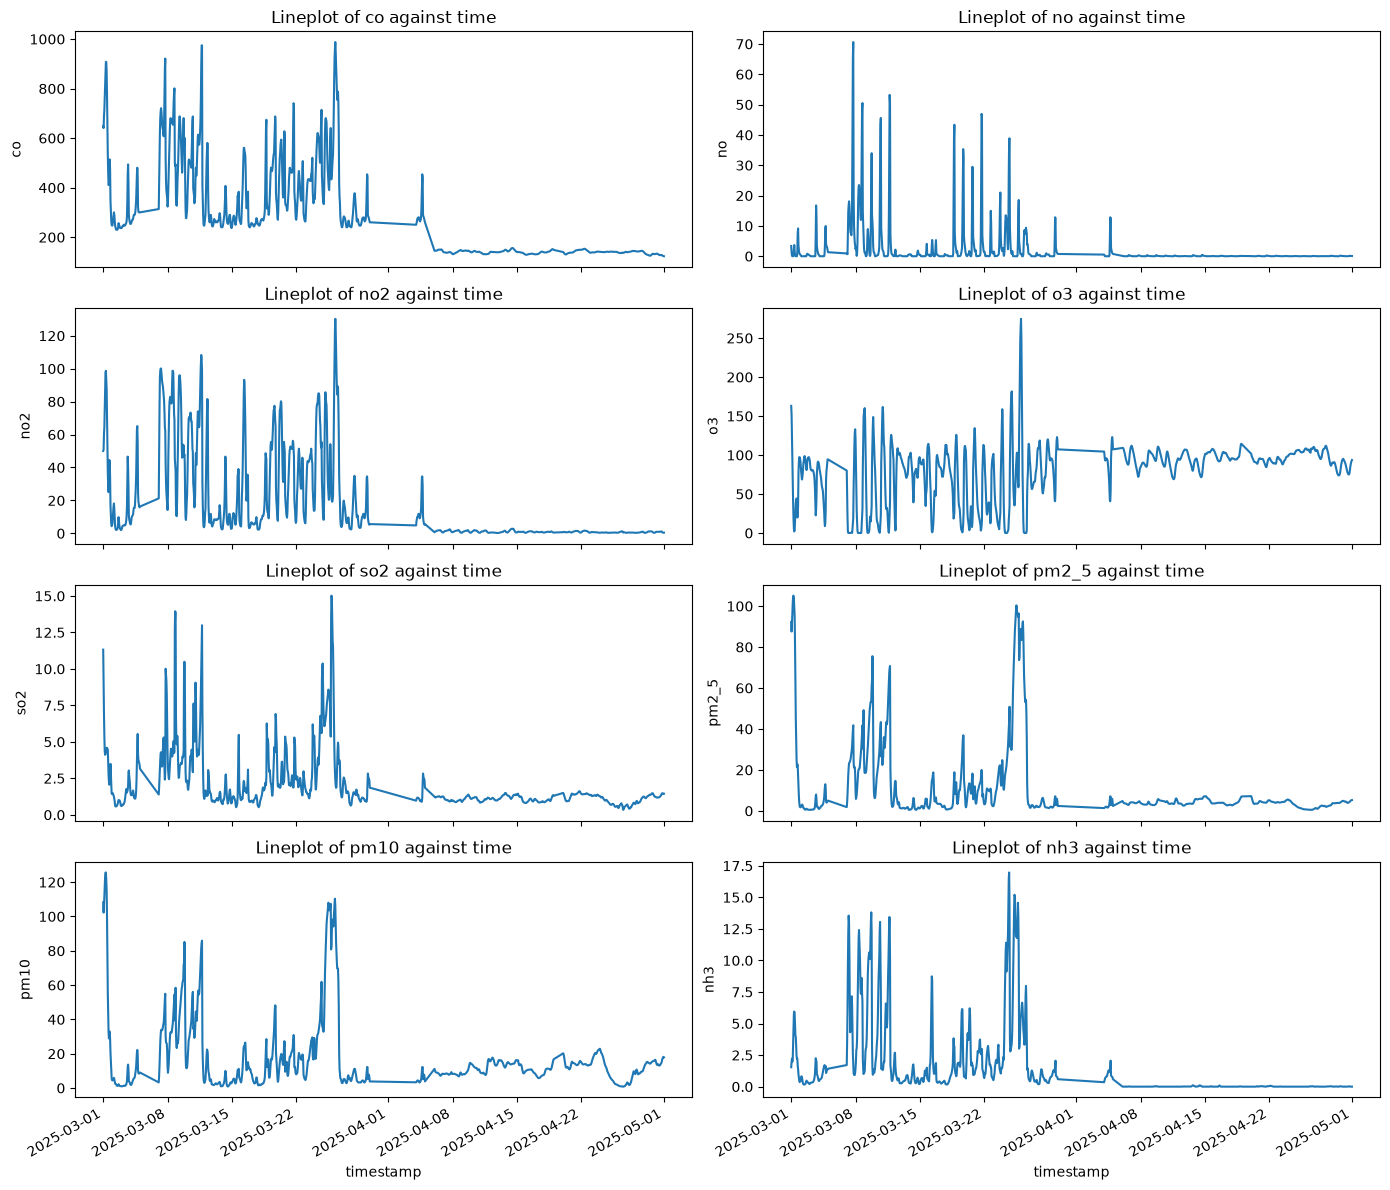

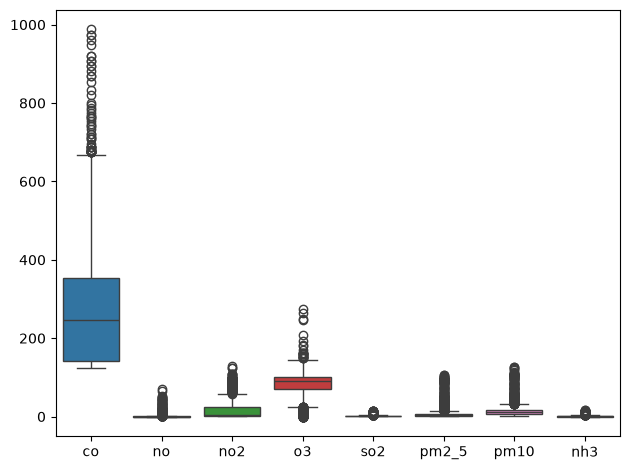

Pollutant plot of San Francisco


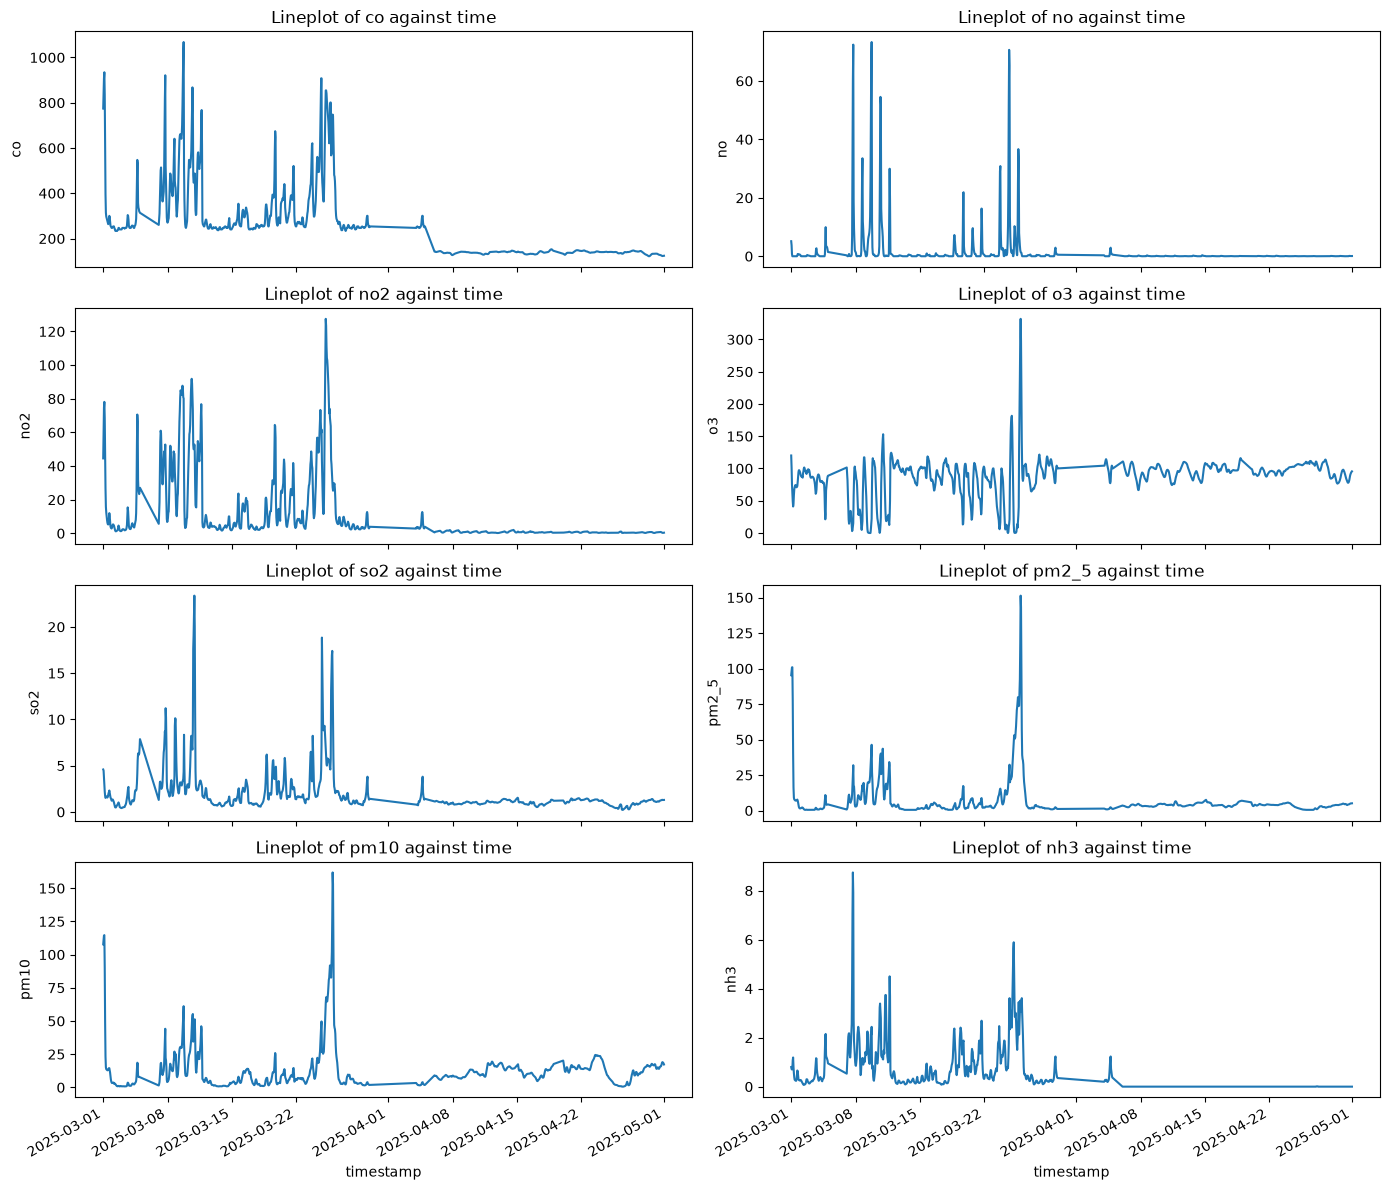

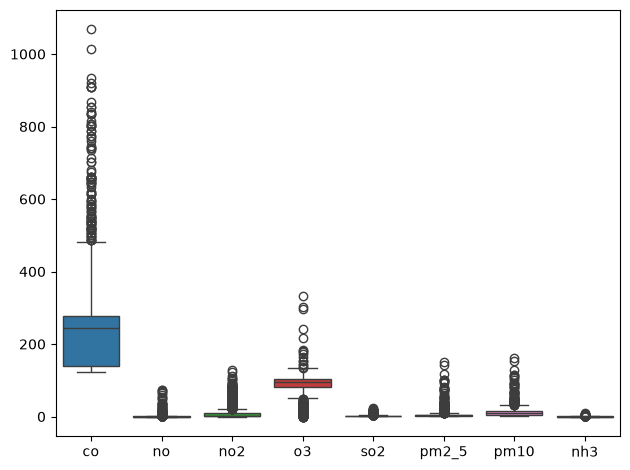

Pollutant plot of Austin


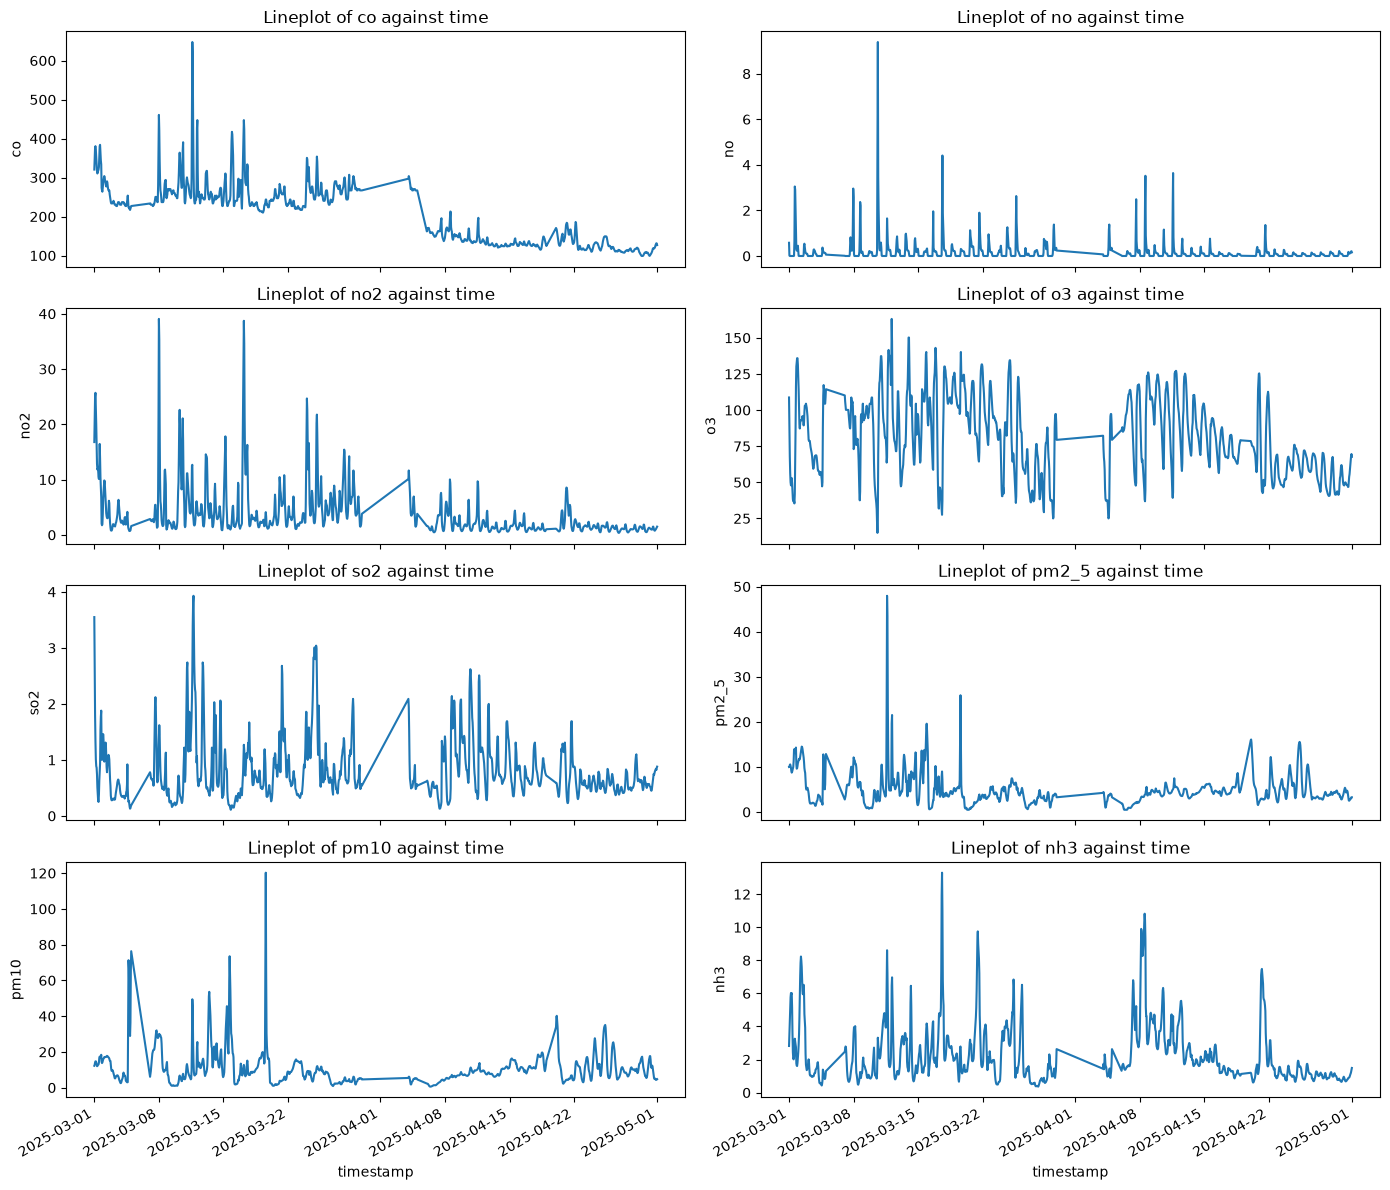

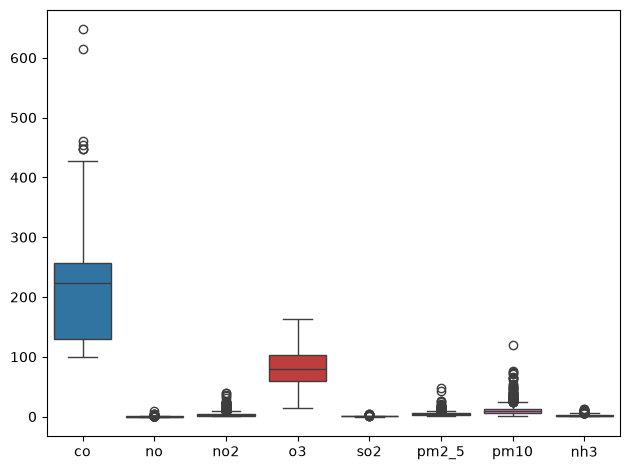

Pollutant plot of Los Angeles


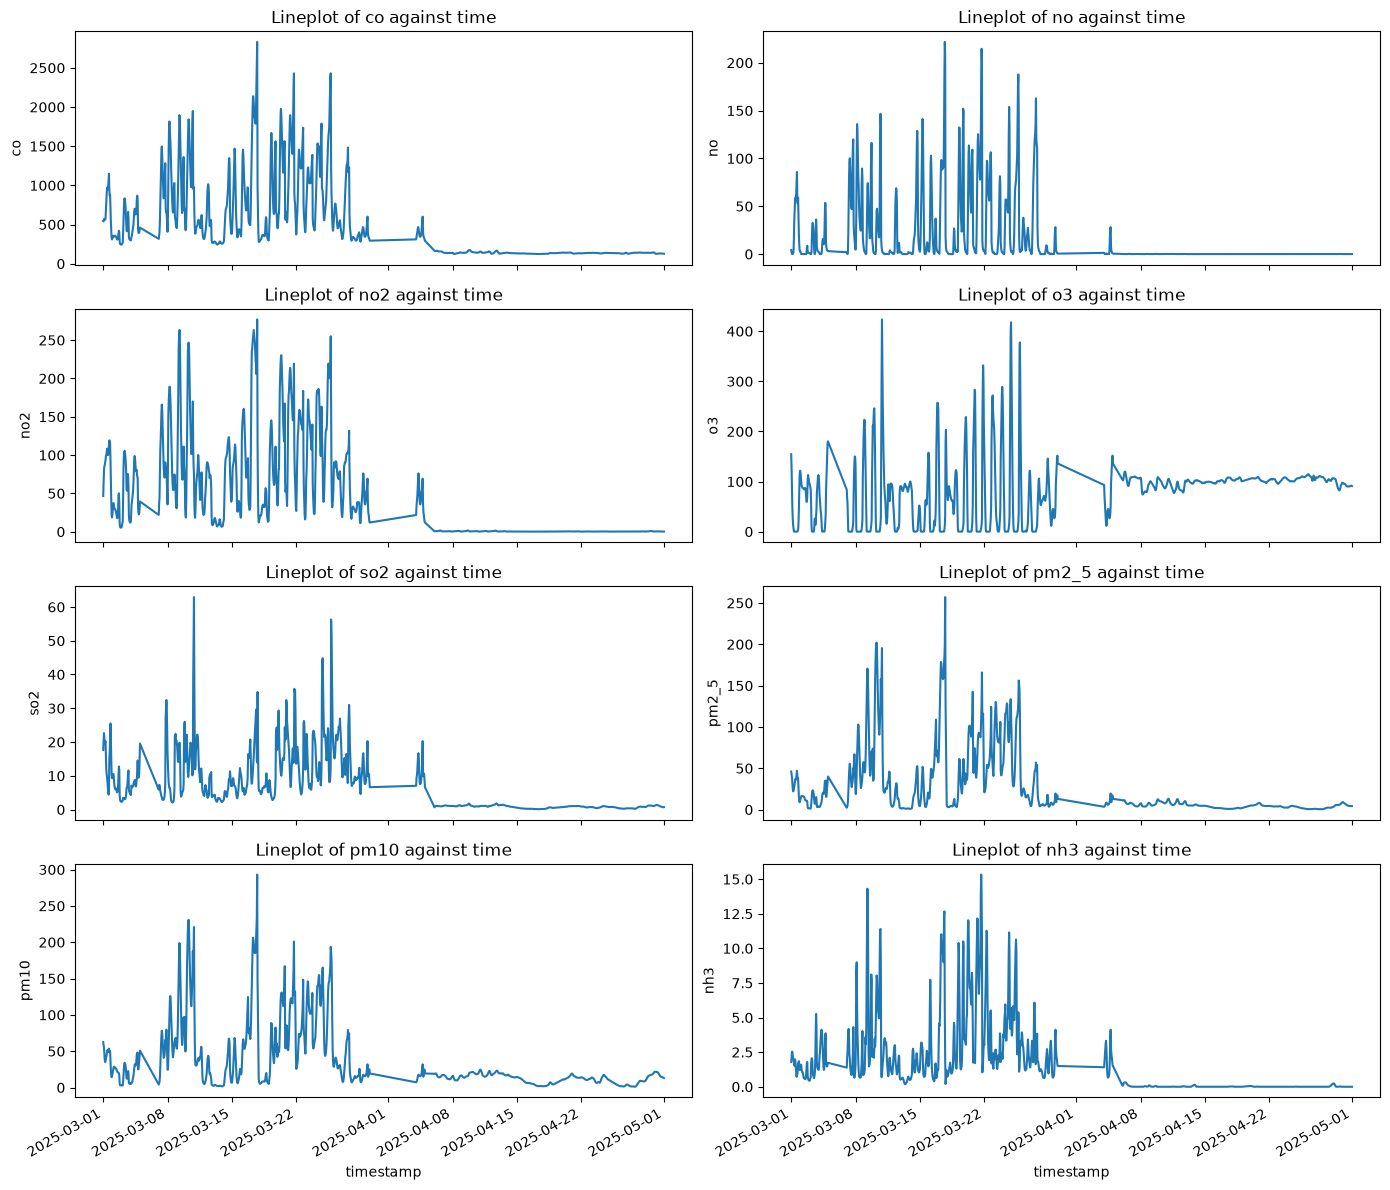

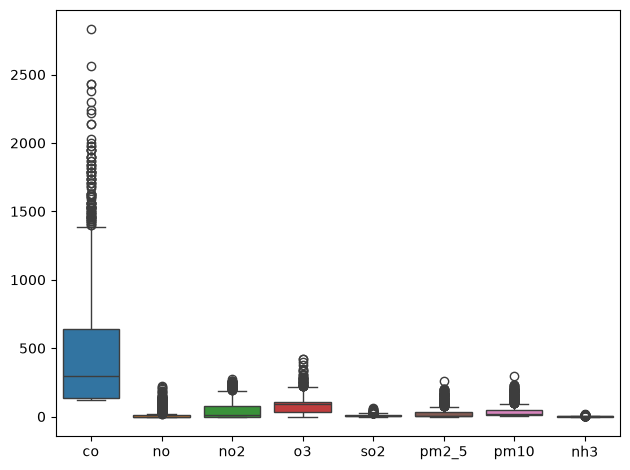

Pollutant plot of Atlanta


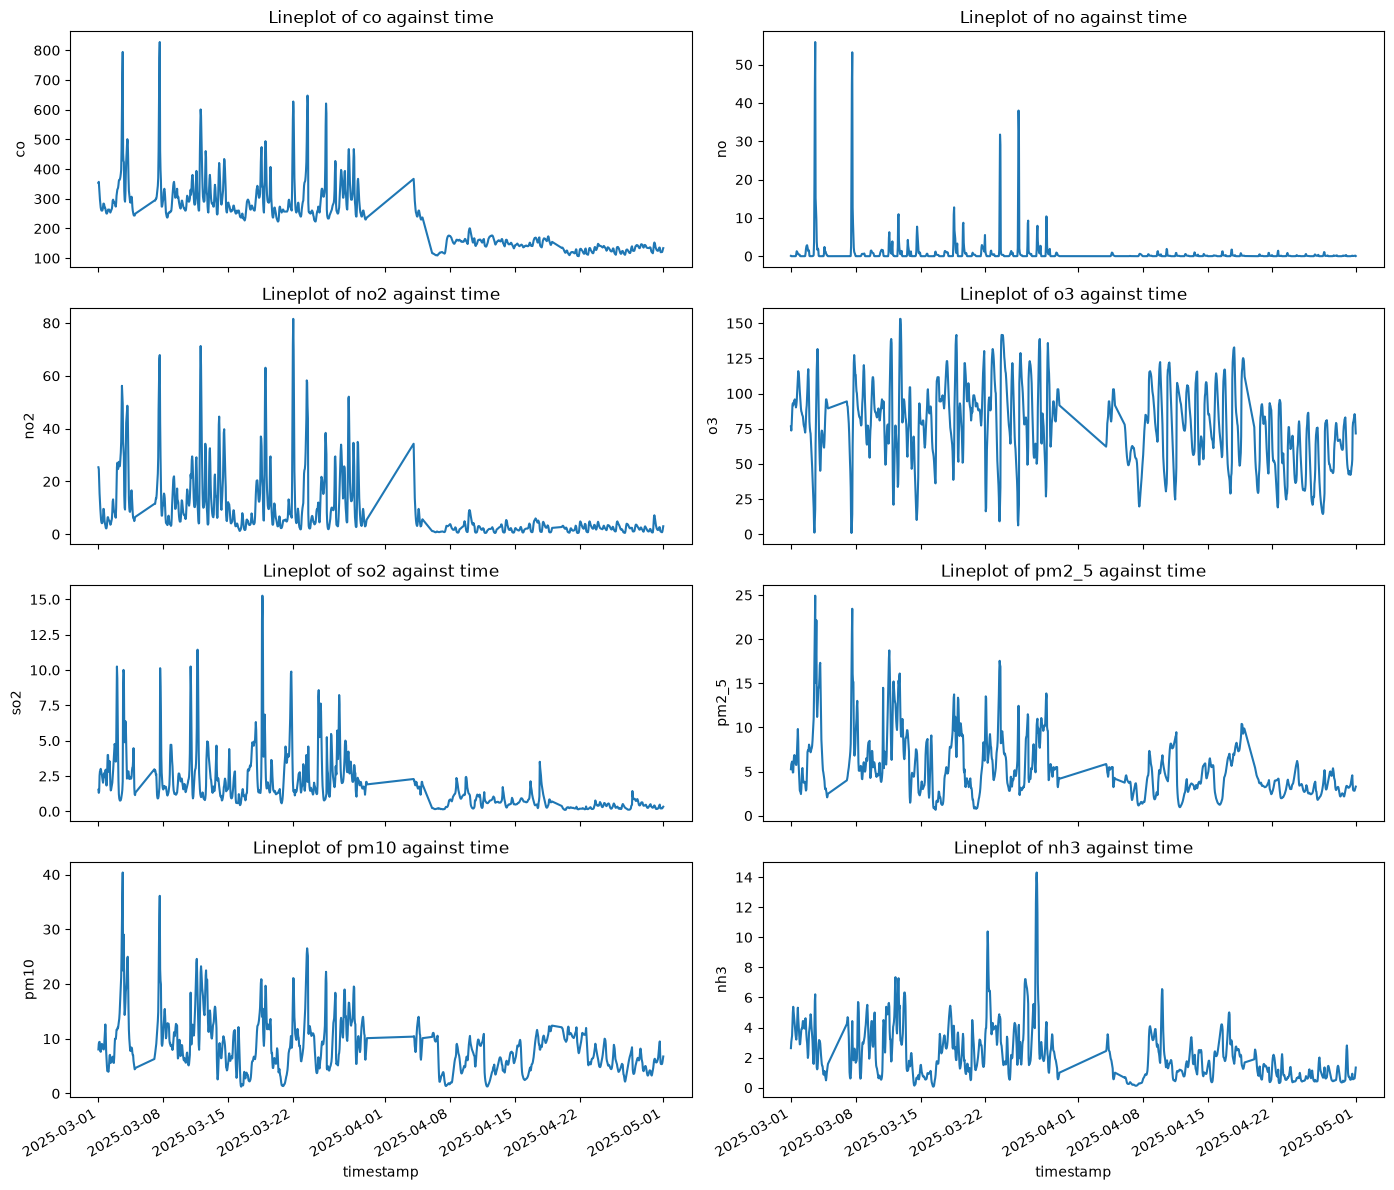

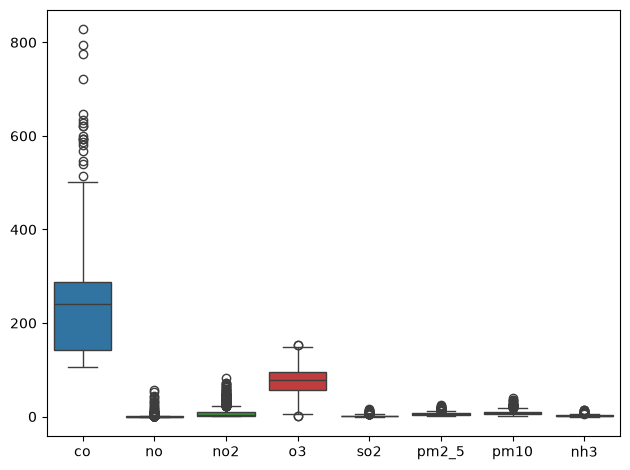

Pollutant plot of Denver


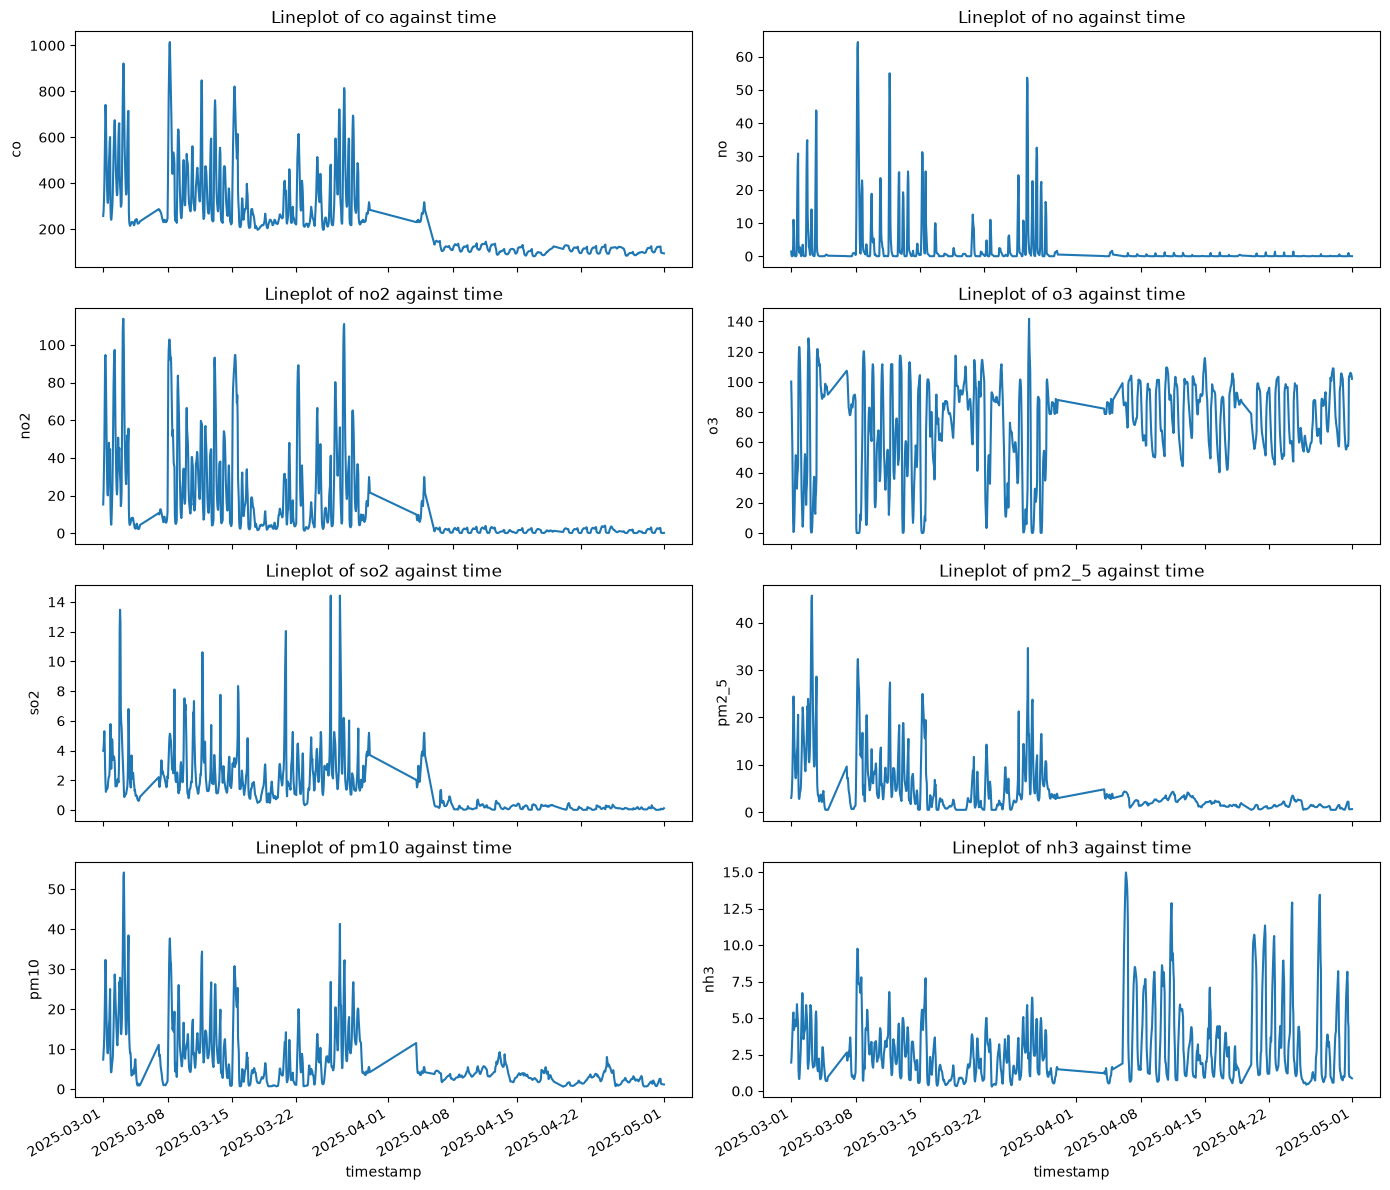

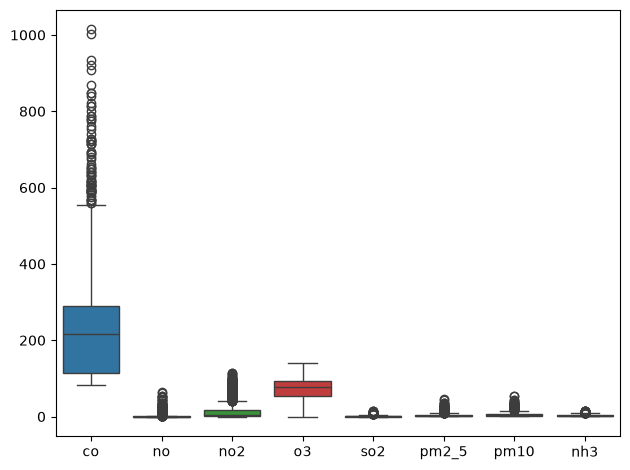

In [24]:
for city in df["city"].unique():
    print(f"Pollutant plot of {city}")
    city_pollutants_lineplot(df, city, time_frame=(datetime(2025, 3, 1, tzinfo=timezone.utc), datetime(2025, 5, 1, tzinfo=timezone.utc)))
    city_pollutants_boxplot(df, city, time_frame=(datetime(2025, 3, 1, tzinfo=timezone.utc), datetime(2025, 5, 1, tzinfo=timezone.utc)))

In [17]:
df.loc[(df["city"] == city) & (df["timestamp"] >= datetime(2025, 4, 1, tzinfo=timezone.utc)), POLLUTANT_COLUMNS].describe()

,co,no,no2,o3,so2,pm2_5,pm10,nh3
count,13615.000000,13615.000000,13615.000000,13615.000000,13615.000000,13615.000000,13615.000000,13615.000000
mean,98.847035,0.084528,1.620637,71.968888,0.174428,2.655711,3.523002,1.312083
std,26.596882,0.216321,1.432173,21.696978,0.204338,4.573959,4.990305,1.801302
min,56.760000,0.000000,0.080000,13.660000,0.000000,0.000000,0.000000,0.000000
25%,83.660000,0.000000,0.380000,55.920000,0.050000,0.890000,1.170000,0.290000
50%,95.450000,0.010000,1.370000,71.320000,0.120000,1.570000,2.190000,0.680000
75%,109.335000,0.050000,2.510000,87.070000,0.240000,2.600000,3.960000,1.500000
max,612.970000,3.430000,29.820000,163.880000,5.190000,78.430000,79.260000,16.400000


Choosing 2025-04-01 as the cut-off for clean data